# Differential Evolution (DE) untuk Optimasi Alokasi Dana Saham LQ45

**Tujuan:** memaksimalkan *expected return* tahunan dengan batas anggaran, risiko, kardinalitas, batas bobot, dan pembelian lot. Notebook ini mengimpor **modul bersama** kelompok.

**Pemisahan data penting:** data **latih** menentukan portofolio dan batas risikonya; data **uji** hanya digunakan untuk mengevaluasi hasil pilihan setelah optimasi selesai. Hasil historis **bukan prediksi keuntungan pasti**.

**Alur:** setup → formulasi → data dan validasi → cara kerja DE → verifikasi K=2 → eksperimen kasus tetap → rincian portofolio/kas → konvergensi/stabilitas → uji buy-and-hold → tiga jendela walk-forward → rekap dan pemeriksaan akhir.

## 1. Setup dan Parameter
Semua aturan (modal, lot, risiko, dan kapasitas K) diambil dari `config.py` dan modul `src/`. Pilih kernel `.venv` proyek pada VS Code.

In [23]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "config.py").exists(), "Buka folder proyek atau jalankan notebook dari folder notebooks/"
for p in (str(ROOT), str(ROOT / 'src')):
    if p not in sys.path: sys.path.insert(0, p)
import config
from algorithms import de
from data import muat_jendela, buat_problem
from decoder import decode
from evaluasi import nilai_uji, metrik_uji
print('Root:', ROOT)
print('DE module:', de.__file__)
print('Anggaran:', config.BUDGET_EVAL, 'evaluasi; kardinalitas:', config.K_LIST)
from algorithms.brute_force_k2 import brute_force_k2
from evaluasi import analisis, rincian_kas, komponen_akhir, nilai_kas, nilai_1n, rp
from IPython.display import display
print('Jumlah jendela tersedia:', config.N_JENDELA)
print('Dana utama:', rp(config.D_UTAMA), '| Lot:', config.LOT_SIZE,
      '| rf tahunan:', f'{config.RISK_FREE:.0%}')

Root: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham
DE module: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\src\algorithms\de.py
Anggaran: 20000 evaluasi; kardinalitas: [2, 3, 5, 7, 10]
Jumlah jendela tersedia: 5
Dana utama: Rp 5.000.000 | Lot: 100 | rf tahunan: 5%


## 2. Formulasi Masalah dan Batasan

Untuk bobot aktual saham:

$$
w_i = \frac{n_i c_i}{D}
$$

dengan:
- $n_i$: jumlah lot saham ke-$i$.
- $c_i$: biaya pembelian satu lot saham ke-$i$.
- $D$: total modal investasi.

**Fungsi objektif — memaksimalkan expected return:**

$$
\max R = \sum_{i=1}^{N} w_i \mu_i + w_{\text{kas}}r_f
$$

**Batas risiko portofolio:**

$$
\sigma_p = \sqrt{\mathbf{w}^{T}\Sigma\mathbf{w}} \leq \sigma_{\max}
$$

dengan:

$$
\sigma_{\max}=1{,}5\,\sigma_{1/N}
$$

**Batas kardinalitas:**

$$
\sum_{i=1}^{N}\mathbb{I}(n_i>0)\leq K
$$

Jumlah saham yang dipilih maksimal $K$, bukan harus tepat $K$.

**Batas modal:**

$$
\sum_{i=1}^{N}n_i c_i\leq D
$$

Sisa modal diperbolehkan menjadi kas.

**Batas bobot saham:**

$$
w_i \leq 0{,}20
$$

Batas bobot 20% berlaku untuk $K=7$ dan $K=10$, sesuai konfigurasi proyek.

**Representasi kromosom:** Setiap kandidat solusi direpresentasikan menggunakan $2N+1$ gen yang kemudian diproses oleh `decoder.py` menjadi jumlah lot, bobot aktual, dan kas.

**Aturan Deb:** solusi memenuhi kendala didahulukan; bila sama-sama layak, dipilih yang return-nya lebih tinggi. Risiko pada data uji tidak dibatasi saat optimasi.


## 3. Data dan Pembentukan Problem
`mu` dan `cov` diperoleh dari data latih; `return_uji` disimpan terpisah. Tahap ini memeriksa ukuran matriks dan pemisahan tanggal.

In [24]:
nama_data='kasus_tetap'
wdata=muat_jendela(nama_data)
P=buat_problem(wdata,K=5)
print('Rentang latih:',wdata['tanggal_latih_awal'],'s.d.',wdata['tanggal_latih_akhir'])
print('Rentang uji  :',wdata['tanggal_uji_awal'],'s.d.',wdata['tanggal_uji_akhir'])
print('N saham:',P.n,'| Gen:',P.n_genes,'| K:',P.K,'| Modal:',rp(P.D))
print('Sigma maksimum:',f'{P.sigma_max:.2%}','| Batas bobot per saham:',f'{P.cap:.0%}')
assert P.n_genes == 2*P.n+1
assert P.cov.shape==(P.n,P.n)
assert wdata['return_uji'].shape[1]==P.n
assert wdata['tanggal_latih_akhir'] < wdata['tanggal_uji_awal']
assert (P.harga_lot>0).all()
display(pd.DataFrame({'Saham':P.tickers,'Harga 1 lot (Rp)':P.harga_lot,'Expected return latih':P.mu,'Vol saham latih':P.vol}).head(12))

Rentang latih: 2021-11-23 s.d. 2025-09-30
Rentang uji  : 2025-10-01 s.d. 2026-09-30
N saham: 42 | Gen: 85 | K: 5 | Modal: Rp 5.000.000
Sigma maksimum: 23.90% | Batas bobot per saham: 100%


,Saham,Harga 1 lot (Rp),Expected return latih,Vol saham latih
0,ACES,43000.0,-0.174186,0.434555
1,ADRO,169000.0,0.385553,0.437822
2,AKRA,121000.0,0.265188,0.403558
3,AMRT,193000.0,0.192656,0.386697
4,ANTM,316000.0,0.220067,0.428310
5,ARTO,213000.0,-0.338139,0.646438
6,ASII,577500.0,0.102340,0.268345
7,BBCA,762500.0,0.058774,0.226241
8,BBNI,410000.0,0.133394,0.297943
9,BBRI,390000.0,0.080920,0.284909


## 4. Pengujian Decoder, Fitness, dan Kelayakan
Memastikan solusi keluaran DE benar-benar berupa jumlah lot bulat, tidak melebihi modal atau batas K, dan nilai evaluasi hasil cocok dengan evaluasi ulang.

In [25]:
from fitness import hitung
from decoder import decode_batch
uji=de.run(P,budget=1000,seed=0)
lots,bobot,kas=decode(uji.x,P)
r,s,v=hitung(lots[None,:],bobot[None,:],np.array([kas]),P)
assert uji.n_eval==1000
assert np.array_equal(lots,uji.lots)
assert np.all(lots>=0) and np.issubdtype(lots.dtype,np.integer)
assert (lots>0).sum()<=P.K
assert (lots*P.harga_lot).sum()<=P.D+1e-6
assert np.all(bobot<=P.cap+1e-9)
assert abs(bobot.sum()+kas-1)<1e-9
assert np.isclose(r[0],uji.R) and np.isclose(s[0],uji.sigma)
assert np.isclose(v[0],uji.viol)
assert uji.feasible
print(f'VALID | R={uji.R:.2%} | risiko={uji.sigma:.2%} / batas={P.sigma_max:.2%} | saham={(lots>0).sum()} | kas={kas:.1%}')

VALID | R=28.63% | risiko=23.80% / batas=23.90% | saham=4 | kas=27.7%


## 5. Algoritma Differential Evolution: DE/rand/1/bin

Setiap individu dalam populasi Differential Evolution (DE) direpresentasikan sebagai vektor kontinu:

$$
\mathbf{x} \in [0,1]^{2N+1}
$$

Dengan $N=42$ saham, setiap individu mempunyai **85 gen** yang nilainya berada pada interval $[0,1]$.

**Mutasi (Mutation)**

Tiga individu berbeda dipilih untuk membentuk vektor mutan:

$$
\mathbf{v} = \mathbf{x}_a + F(\mathbf{x}_b-\mathbf{x}_c)
$$

Nilai setiap komponen vektor mutan kemudian dibatasi pada interval $[0,1]$.

**Crossover binomial**

Vektor mutan digabungkan dengan vektor target untuk membentuk kandidat solusi baru (*trial vector*). Setidaknya satu gen wajib diambil dari vektor mutan.

**Seleksi (Selection)**

Kandidat baru dibandingkan dengan individu sebelumnya menggunakan aturan kelayakan Deb. Solusi yang lebih baik dipertahankan untuk generasi berikutnya.

**Parameter dasar:**

- Ukuran populasi: 100 individu.
- Faktor mutasi: $F=0{,}5$.
- Probabilitas crossover: $CR=0{,}9$.
- Anggaran komputasi: **20.000 evaluasi fitness**.

Parameter tersebut merupakan konfigurasi awal eksperimen dan belum tentu merupakan kombinasi parameter yang paling optimal.

In [15]:
print('Parameter DE:',de.DE_PARAM)
print('Anggaran utama:',config.BUDGET_EVAL)
# Lihat sumber algoritma secara langsung di src/algorithms/de.py; tidak disalin agar tidak ada duplikasi.

Parameter DE: {'pop': 100, 'F': 0.5, 'CR': 0.9, 'n_seed': 0}
Anggaran utama: 20000


## 6. Verifikasi terhadap Brute Force K=2
Brute force adalah acuan untuk **kas bebas** dengan pembatasan K≤2. Selisih terhadap optimum dapat mengukur kualitas DE pada kasus kecil. Enumerasi penuh dapat memerlukan waktu lebih lama, jadi **dimatikan secara default**. Aktifkan `JALANKAN_BRUTE_FORCE = True` hanya jika ingin membandingkan secara eksak.

In [26]:
JALANKAN_BRUTE_FORCE = True  # ubah ke True jika ingin validasi tambahan
if JALANKAN_BRUTE_FORCE:
    P2=buat_problem(wdata,K=2)
    t0=time.perf_counter()
    acuan=brute_force_k2(P2)['kas bebas']
    de2=de.run(P2,budget=config.BUDGET_EVAL,seed=0)
    gap=max(0.0,acuan[0]-de2.R)
    print('Optimum brute-force:',f'{acuan[0]:.4%}')
    print('Return DE:',f'{de2.R:.4%}','| Gap absolut:',f'{gap:.4%}')
    print('Waktu brute force:',round(time.perf_counter()-t0,2),'detik (termasuk DE)')
else:
    print('Brute force dilewati. Untuk validasi opsional, set JALANKAN_BRUTE_FORCE=True.')

Optimum brute-force: 29.6576%
Return DE: 29.6269% | Gap absolut: 0.0308%
Waktu brute force: 0.45 detik (termasuk DE)


## 7. Eksperimen Utama (Kasus Tetap)
Secara **default**, digunakan **30 seed**. Untuk uji cepat bisa sementara gunakan 3 seed. Tujuannya melihat kualitas optimasi, kestabilan antarrun, dan waktu eksekusi.

In [27]:
N_SEED_TETAP=30
KS_TETAP=[2,3,5,7,10]
BUDGET_TETAP=config.BUDGET_EVAL
hasil_tetap=[]; kandidat_tetap={}; histori_tetap={}
t0=time.perf_counter()
for K in KS_TETAP:
    pk=buat_problem(wdata,K=K)
    for seed in range(N_SEED_TETAP):
        result=de.run(pk,budget=BUDGET_TETAP,seed=seed)
        nilai=nilai_uji(pk,result.lots,wdata['return_uji'])
        m=metrik_uji(nilai,pk.D)
        hasil_tetap.append(dict(K=K,seed=seed,return_latih=result.R,risiko_latih=result.sigma,
                                valid_latih=result.feasible,waktu_detik=result.seconds,
                                eval_terbaik=result.n_eval_best,n_eval=result.n_eval,
                                saham_aktual=int((result.lots>0).sum()),
                                kas=(pk.D-(result.lots*pk.harga_lot).sum())/pk.D,
                                return_uji=m['setara_tahun'],risiko_uji=m['vol'],max_drawdown=m['mdd']))
        kandidat_tetap[(K,seed)]=(pk,result)
        histori_tetap[(K,seed)]=result.history
    print(f'K={K}: {N_SEED_TETAP} seed selesai')
df_tetap=pd.DataFrame(hasil_tetap)
print('Total run:',len(df_tetap),'| waktu proses:',round(time.perf_counter()-t0,2),'detik')
display(df_tetap.groupby('K').agg(n_run=('seed','count'),median_return=('return_latih','median'),
       std_return=('return_latih','std'),kelayakan=('valid_latih','mean'),
       median_waktu=('waktu_detik','median'),median_kas=('kas','median'),
       median_return_uji=('return_uji','median')).reset_index())
# Ekspor kasus tetap secara terpisah dari hasil walk-forward
outdir=ROOT/"hasil"/"csv"; outdir.mkdir(parents=True,exist_ok=True)
df_tetap.to_csv(outdir/"de_kasus_tetap_30seed.csv",index=False)

K=2: 30 seed selesai
K=3: 30 seed selesai
K=5: 30 seed selesai
K=7: 30 seed selesai
K=10: 30 seed selesai
Total run: 150 | waktu proses: 38.48 detik


,K,n_run,median_return,std_return,kelayakan,median_waktu,median_kas,median_return_uji
0,2,30,0.295037,0.000493,1.0,0.220710,0.39580,0.024369
1,3,30,0.322292,0.003617,1.0,0.229942,0.30000,0.100879
2,5,30,0.336377,0.001790,1.0,0.231530,0.22120,0.035885
3,7,30,0.337801,0.001526,1.0,0.288968,0.10070,0.078137
4,10,30,0.337801,0.001586,1.0,0.274612,0.09805,0.085561


## 8. Visualisasi Konvergensi dan Kestabilan
**Konvergensi**: kapan solusi terbaik ditemukan selama evaluasi. **Boxplot**: variasi return antar seed. K=2 bisa memiliki variasi sangat kecil karena banyak seed mencapai solusi sama.

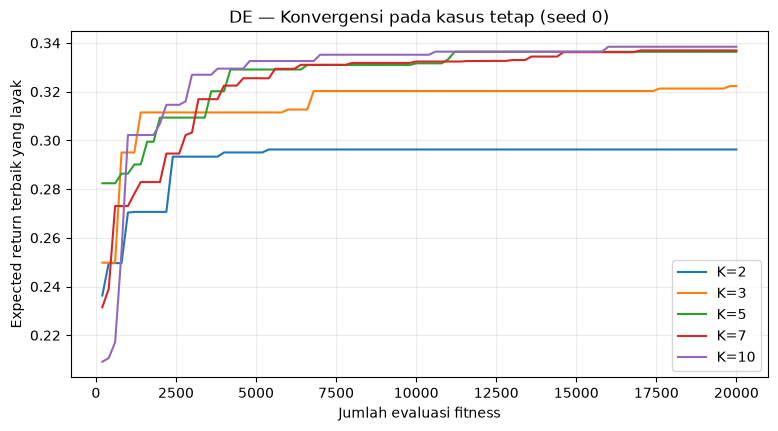

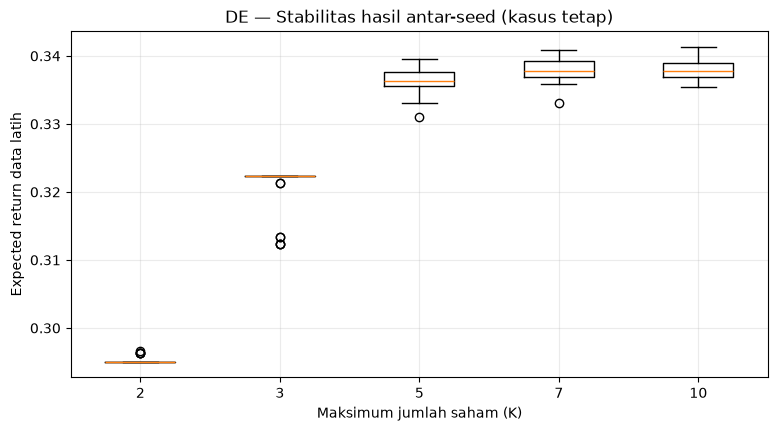

In [28]:
fig,ax=plt.subplots(figsize=(9,4.5))
for K in KS_TETAP:
    h=np.asarray(histori_tetap[(K,0)],dtype=float)
    ax.plot(h[:,0],h[:,1],label=f'K={K}')
ax.set(xlabel='Jumlah evaluasi fitness',ylabel='Expected return terbaik yang layak',title='DE — Konvergensi pada kasus tetap (seed 0)')
ax.grid(alpha=.25);ax.legend();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
ax.boxplot([df_tetap.loc[df_tetap.K==k,'return_latih'].values for k in KS_TETAP],tick_labels=[str(k) for k in KS_TETAP])
ax.set(xlabel='Maksimum jumlah saham (K)',ylabel='Expected return data latih',title='DE — Stabilitas hasil antar-seed (kasus tetap)')
ax.grid(alpha=.25);plt.show()

## 9. Pemilihan Saham, Lot, Bobot, dan Rincian Sisa Kas
Bagian ini menunjukkan **saham apa yang dibeli**, berapa lot, biaya, kontribusi return, dan komponen kas. Kandidat representatif dipilih sebagai **return latih terbaik yang feasible** untuk tiap K.

In [29]:
contoh_rows=[]; portofolio_terpilih={}
for K in KS_TETAP:
    layak=df_tetap[(df_tetap.K==K)&(df_tetap.valid_latih)]
    if layak.empty:continue
    row=layak.sort_values(['return_latih','seed'],ascending=[False,True]).iloc[0]
    seed=int(row.seed);pk,r=kandidat_tetap[(K,seed)]
    portofolio_terpilih[K]=(pk,r)
    lot=r.lots;detail=analisis(pk,lot);rk=rincian_kas(r.x,pk)
    contoh_rows.append({'K':K,'seed':seed,'n_saham':int((lot>0).sum()),'dana_saham_Rp':rk['terpakai'],
                        'kas_Rp':rk['kas_akhir'],'return_latih':r.R,'risiko_latih':r.sigma,'eval_terbaik':r.n_eval_best})
display(pd.DataFrame(contoh_rows))
K_CONTOH=5
pc,rc=portofolio_terpilih[K_CONTOH]
a=analisis(pc,rc.lots)
mask=rc.lots>0
detail=pd.DataFrame({'saham':np.array(pc.tickers)[mask], 'lot':rc.lots[mask],
 'harga_per_lot_Rp':pc.harga_lot[mask], 'biaya_Rp':(rc.lots*pc.harga_lot)[mask],
 'bobot':a['w'][mask],'mu_saham':pc.mu[mask],'kontribusi_return':a['R_saham'][mask]})
print('Contoh rincian K=',K_CONTOH)
display(detail.sort_values('biaya_Rp',ascending=False))
print('Rincian kas:',rincian_kas(rc.x,pc))
print('R portofolio:',f"{a['R']:.2%}",'= kontribusi saham',f"{a['R_saham'].sum():.2%}",'+ kontribusi kas',f"{a['R_kas']:.2%}")

,K,seed,n_saham,dana_saham_Rp,kas_Rp,return_latih,risiko_latih,eval_terbaik
0,2,7,2,3787500.0,1212500.0,0.296576,0.237750,2060
1,3,0,3,3500000.0,1500000.0,0.322292,0.238474,19746
2,5,6,5,4042500.0,957500.0,0.339544,0.237976,17406
3,7,13,7,4584500.0,415500.0,0.340879,0.238790,18527
4,10,29,7,4635500.0,364500.0,0.341344,0.238752,14047


Contoh rincian K= 5


,saham,lot,harga_per_lot_Rp,biaya_Rp,bobot,mu_saham,kontribusi_return
0,ADRO,7,169000.0,1183000.0,0.2366,0.385553,0.091222
1,BRPT,3,375000.0,1125000.0,0.2250,0.526540,0.118471
4,MEDC,6,137000.0,822000.0,0.1644,0.427032,0.070204
3,MAPI,5,112500.0,562500.0,0.1125,0.203180,0.022858
2,ESSA,5,70000.0,350000.0,0.0700,0.388775,0.027214


Rincian kas: {'modal': 5000000.0, 'terpakai': 4042500.0, 'kas_akhir': 957500.0, 'kas_sengaja': 374893.6224190916, 'kas_cap': 0.0, 'kas_pembulatan': 582606.3775809084}
R portofolio: 33.95% = kontribusi saham 33.00% + kontribusi kas 0.96%


## 10. Nilai Investasi Akhir berdasarkan Return yang Diharapkan (Data Latih)
Nilai ini adalah **ilustrasi satu tahun berdasarkan expected return latih**. Untuk investasi aktual historis, lihat bagian evaluasi data uji di bawah.

In [30]:
proyeksi=[]
for K,(pk,r) in portofolio_terpilih.items():
    a=analisis(pk,r.lots)
    proyeksi.append({'K':K,'modal_Rp':pk.D,'nilai_saham_awal_Rp':float((r.lots*pk.harga_lot).sum()),
                    'kas_awal_Rp':float(pk.D-(r.lots*pk.harga_lot).sum()),
                    'return_ekspektasi':a['R'],'ilustrasi_nilai_akhir_Rp':pk.D*(1+a['R'])})
display(pd.DataFrame(proyeksi))

,K,modal_Rp,nilai_saham_awal_Rp,kas_awal_Rp,return_ekspektasi,ilustrasi_nilai_akhir_Rp
0,2,5000000.0,3787500.0,1212500.0,0.296576,6.482881e+06
1,3,5000000.0,3500000.0,1500000.0,0.322292,6.611460e+06
2,5,5000000.0,4042500.0,957500.0,0.339544,6.697722e+06
3,7,5000000.0,4584500.0,415500.0,0.340879,6.704397e+06
4,10,5000000.0,4635500.0,364500.0,0.341344,6.706720e+06


## 11. Evaluasi Out-of-Sample: Buy-and-Hold pada Kasus Tetap
Portofolio dipilih **hanya** dari data latih. Nilainya dievaluasi pada periode uji, tanpa reoptimasi. Pembanding visual adalah modal awal, seluruh kas berbunga rf, dan 1/N ideal sebagai **referensi indikatif**. Return tahunan dihitung menurut fungsi bersama `metrik_uji`.

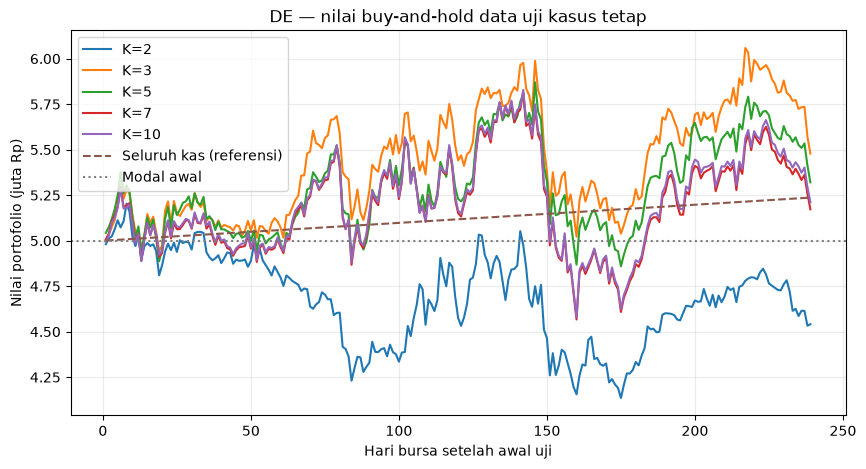

,K,seed,return_total_uji,return_setara_tahun,vol_uji,max_drawdown,nilai_saham_akhir_Rp,nilai_kas_akhir_Rp,nilai_total_akhir_Rp,memenuhi_batas_risiko_uji
0,2,7,-0.091742,-0.096732,0.233553,-0.205256,3.271366e+06,1.269925e+06,4.541291e+06,True
1,3,0,0.095675,0.100879,0.246449,-0.161419,3.907333e+06,1.571041e+06,5.478374e+06,False
2,5,6,0.064116,0.067604,0.251357,-0.172264,4.317733e+06,1.002848e+06,5.320581e+06,False
3,7,13,0.034507,0.036384,0.264089,-0.214645,4.737358e+06,4.351783e+05,5.172536e+06,False
4,10,29,0.042399,0.044706,0.263747,-0.214476,4.830234e+06,3.817629e+05,5.211997e+06,False


In [31]:
baris_uji=[]
fig,ax=plt.subplots(figsize=(10,5))
for K,(pk,r) in portofolio_terpilih.items():
    nilai=nilai_uji(pk,r.lots,wdata['return_uji'])
    m=metrik_uji(nilai,pk.D)
    sah,kas_akhir=komponen_akhir(pk,r.lots,wdata['return_uji'])
    baris_uji.append({'K':K,'seed':r.seed,'return_total_uji':m['total'],
      'return_setara_tahun':m['setara_tahun'],'vol_uji':m['vol'],'max_drawdown':m['mdd'],
      'nilai_saham_akhir_Rp':sah,'nilai_kas_akhir_Rp':kas_akhir,'nilai_total_akhir_Rp':nilai[-1],
      'memenuhi_batas_risiko_uji':m['vol']<=pk.sigma_max})
    ax.plot(range(1,len(nilai)+1),nilai/1e6,label=f'K={K}')
T=len(wdata['return_uji'])
ax.plot(range(1,T+1),nilai_kas(config.D_UTAMA,config.RISK_FREE,T)/1e6,'--',label='Seluruh kas (referensi)')
ax.axhline(config.D_UTAMA/1e6,color='gray',ls=':',label='Modal awal')
ax.set(xlabel='Hari bursa setelah awal uji',ylabel='Nilai portofolio (juta Rp)',title='DE — nilai buy-and-hold data uji kasus tetap')
ax.legend();ax.grid(alpha=.25);plt.show()
display(pd.DataFrame(baris_uji))

## 12. Walk-Forward: 3 jendela × 5 K × 10 seed
Hasil berikut adalah eksperimen tambahan lintas periode. Tiap jendela memakai statistik latihnya sendiri; data uji **tidak ikut** dipakai untuk memilih kandidat. Set `MODE='cek'` untuk pemeriksaan cepat, atau `MODE='lengkap'` untuk 150 run.

In [32]:
MODE = 'lengkap'   # 'cek' atau 'lengkap'
WINDOWS = ['jendela_1', 'jendela_2', 'jendela_3'] if MODE == 'lengkap' else ['jendela_1']
KS = [2, 3, 5, 7, 10] if MODE == 'lengkap' else [5]
SEEDS = range(10) if MODE == 'lengkap' else range(1)
BUDGET = 20_000 if MODE == 'lengkap' else 1000
print('Total run:', len(WINDOWS)*len(KS)*len(SEEDS))

Total run: 150


In [33]:
records=[]
portofolio=[]
histories=[]
started=time.perf_counter()
for nama in WINDOWS:
    wdata=muat_jendela(nama)
    for K in KS:
        problem=buat_problem(wdata,K=K)
        for seed in SEEDS:
            result=de.run(problem,budget=BUDGET,seed=seed)
            lots,bobot,kas=decode(result.x,problem)
            nilai=nilai_uji(problem,result.lots,wdata['return_uji'])
            out=metrik_uji(nilai,problem.D)
            # Periode uji bukan pelatihan: evaluasi risiko aktual, bukan constraint keras saat mencari.
            row=dict(algoritma='DE',jendela=nama,K=K,seed=seed,modal=problem.D,
                     sigma_max=problem.sigma_max,return_latih=result.R,risiko_latih=result.sigma,
                     valid_latih=bool(result.feasible),n_eval=result.n_eval,
                     eval_terbaik=result.n_eval_best,waktu_detik=result.seconds,
                     jumlah_saham=int((lots>0).sum()),porsi_kas=float(kas),
                     return_uji_total=out['total'],return_uji_tahunan=out['setara_tahun'],
                     risiko_uji=out['vol'],max_drawdown=out['mdd'],
                     risiko_uji_memenuhi=bool(out['vol'] <= problem.sigma_max),
                     tanggal_uji_awal=wdata['tanggal_uji_awal'],tanggal_uji_akhir=wdata['tanggal_uji_akhir'])
            records.append(row)
            portofolio.append(dict(jendela=nama,K=K,seed=seed,
                                  lots=';'.join(map(str,lots)),tickers=';'.join(problem.tickers)))
            histories.extend(dict(jendela=nama,K=K,seed=seed,n_eval=n,return_terbaik=R)
                             for n,R in result.history)
        print(f'{nama} K={K}: {len(SEEDS)} seed selesai')
df=pd.DataFrame(records)
outdir=ROOT/'hasil'/'csv';outdir.mkdir(parents=True,exist_ok=True)
df.to_csv(outdir/'de_walkforward.csv',index=False)
pd.DataFrame(portofolio).to_csv(outdir/'de_portofolio_lot.csv',index=False)
pd.DataFrame(histories).to_csv(outdir/'de_konvergensi.csv',index=False)
print('Selesai:',len(df),'run | waktu total:',round(time.perf_counter()-started,1),'detik')
print('CSV tersimpan ke',outdir)
display(df.head())

jendela_1 K=2: 10 seed selesai
jendela_1 K=3: 10 seed selesai
jendela_1 K=5: 10 seed selesai
jendela_1 K=7: 10 seed selesai
jendela_1 K=10: 10 seed selesai
jendela_2 K=2: 10 seed selesai
jendela_2 K=3: 10 seed selesai
jendela_2 K=5: 10 seed selesai
jendela_2 K=7: 10 seed selesai
jendela_2 K=10: 10 seed selesai
jendela_3 K=2: 10 seed selesai
jendela_3 K=3: 10 seed selesai
jendela_3 K=5: 10 seed selesai
jendela_3 K=7: 10 seed selesai
jendela_3 K=10: 10 seed selesai
Selesai: 150 run | waktu total: 37.5 detik
CSV tersimpan ke c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\hasil\csv


,algoritma,jendela,K,seed,modal,sigma_max,return_latih,risiko_latih,valid_latih,n_eval,...,waktu_detik,jumlah_saham,porsi_kas,return_uji_total,return_uji_tahunan,risiko_uji,max_drawdown,risiko_uji_memenuhi,tanggal_uji_awal,tanggal_uji_akhir
0,DE,jendela_1,2,0,5000000.0,0.204796,0.339797,0.199322,True,20000,...,0.268972,2,0.304,0.025251,0.050503,0.133941,-0.060685,True,2023-12-15,2024-07-09
1,DE,jendela_1,2,1,5000000.0,0.204796,0.339797,0.199322,True,20000,...,0.300203,2,0.304,0.025251,0.050503,0.133941,-0.060685,True,2023-12-15,2024-07-09
2,DE,jendela_1,2,2,5000000.0,0.204796,0.339797,0.199322,True,20000,...,0.218904,2,0.304,0.025251,0.050503,0.133941,-0.060685,True,2023-12-15,2024-07-09
3,DE,jendela_1,2,3,5000000.0,0.204796,0.339797,0.199322,True,20000,...,0.232714,2,0.304,0.025251,0.050503,0.133941,-0.060685,True,2023-12-15,2024-07-09
4,DE,jendela_1,2,4,5000000.0,0.204796,0.339797,0.199322,True,20000,...,0.222286,2,0.304,0.025251,0.050503,0.133941,-0.060685,True,2023-12-15,2024-07-09


## 13. Rekap per Jendela: Return Latih, Stabilitas, Risiko, dan Return Uji

In [34]:
rekap=(df.groupby(['jendela','K']).agg(
    n_run=('return_latih','size'),
    median_return_latih=('return_latih','median'),
    std_return_latih=('return_latih','std'),
    tingkat_kelayakan=('valid_latih','mean'),
    median_waktu=('waktu_detik','median'),
    median_kas=('porsi_kas','median'),
    median_jumlah_saham=('jumlah_saham','median'),
    median_return_uji=('return_uji_tahunan','median'),
    median_vol_uji=('risiko_uji','median'),
    proporsi_memenuhi_risiko_uji=('risiko_uji_memenuhi','mean')).reset_index())
display(rekap)
rekap.to_csv(outdir/'de_rekap_walkforward.csv',index=False)

,jendela,K,n_run,median_return_latih,std_return_latih,tingkat_kelayakan,median_waktu,median_kas,median_jumlah_saham,median_return_uji,median_vol_uji,proporsi_memenuhi_risiko_uji
0,jendela_1,2,10,0.339797,0.000000,1.0,0.222352,0.304000,2.0,0.050503,0.133941,1.0
1,jendela_1,3,10,0.377478,0.007558,1.0,0.223806,0.095500,3.0,0.119015,0.181276,1.0
2,jendela_1,5,10,0.436205,0.003615,1.0,0.228342,0.081450,5.0,0.045017,0.170500,1.0
3,jendela_1,7,10,0.435136,0.003620,1.0,0.276380,0.068826,6.0,0.136012,0.163675,1.0
4,jendela_1,10,10,0.434673,0.001842,1.0,0.277158,0.071652,6.0,0.121785,0.164345,1.0
5,jendela_2,2,10,0.309209,0.010351,1.0,0.217045,0.194500,2.0,-0.146594,0.227587,0.0
6,jendela_2,3,10,0.360245,0.000000,1.0,0.217074,0.186575,3.0,-0.168314,0.210131,0.0
7,jendela_2,5,10,0.379504,0.002305,1.0,0.216778,0.071325,5.0,-0.154506,0.203081,0.3
8,jendela_2,7,10,0.372122,0.003119,1.0,0.277406,0.065975,6.0,-0.104323,0.187847,1.0
9,jendela_2,10,10,0.371420,0.002456,1.0,0.273931,0.061825,7.0,-0.129842,0.191840,1.0


## 14. Visualisasi Perbandingan K dan Periode Pengujian

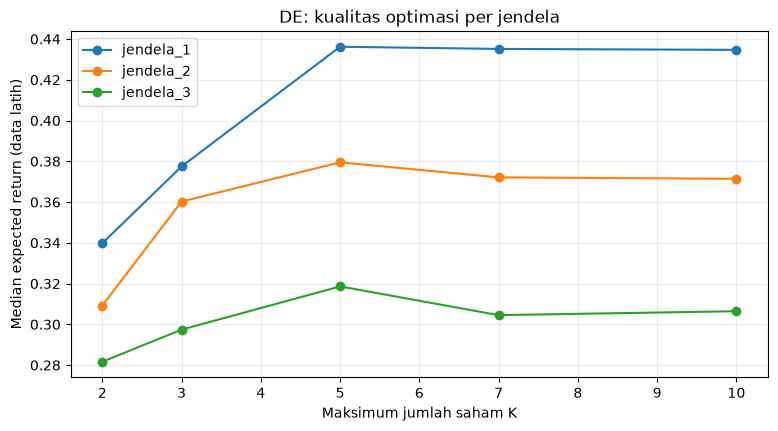

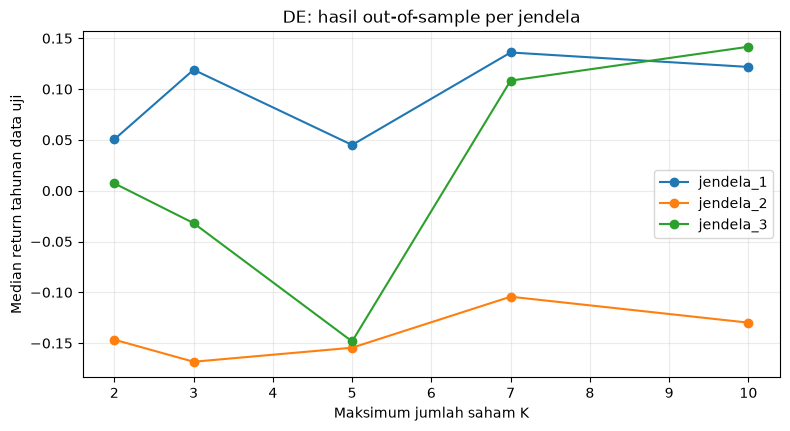

In [35]:
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g['K'],g['median_return_latih'],marker='o',label=nama)
ax.set(xlabel='Maksimum jumlah saham K',ylabel='Median expected return (data latih)',title='DE: kualitas optimasi per jendela')
ax.grid(alpha=.25);ax.legend();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g['K'],g['median_return_uji'],marker='o',label=nama)
ax.set(xlabel='Maksimum jumlah saham K',ylabel='Median return tahunan data uji',title='DE: hasil out-of-sample per jendela')
ax.grid(alpha=.25);ax.legend();plt.show()

## 15. Diagnostik Tambahan: Sebaran Seed, Waktu Eksekusi, dan Hasil Uji
Grafik berikut memeriksa apakah return latih yang tinggi secara konsisten berhubungan dengan hasil data uji.

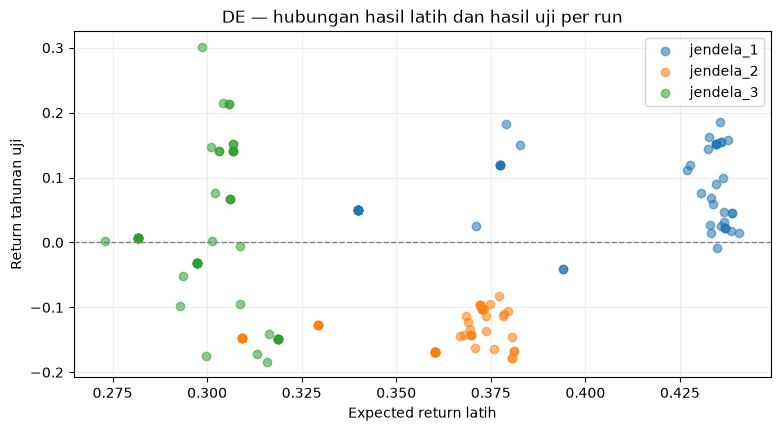

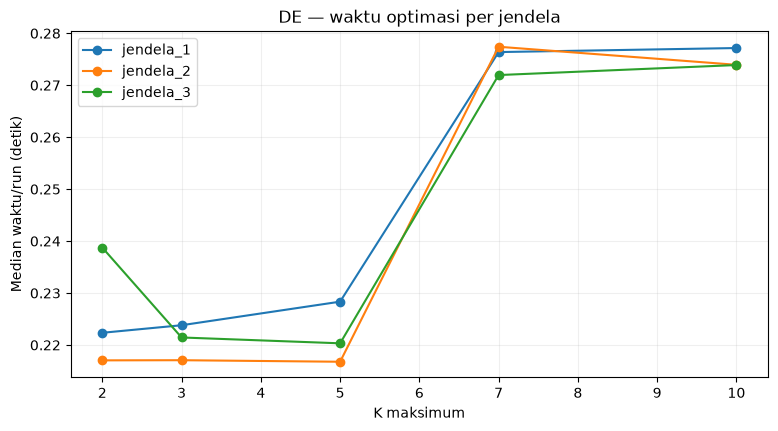

Jumlah run latih feasible: 150 dari 150
Jumlah run risiko UJI memenuhi: 73 dari 150


In [37]:
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in df.groupby('jendela'):
    ax.scatter(g['return_latih'],g['return_uji_tahunan'],alpha=.55,label=nama)
ax.axhline(0,color='gray',ls='--',lw=1)
ax.set(xlabel='Expected return latih',ylabel='Return tahunan uji',title='DE — hubungan hasil latih dan hasil uji per run')
ax.grid(alpha=.2);ax.legend();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g.K,g.median_waktu,marker='o',label=nama)
ax.set(xlabel='K maksimum',ylabel='Median waktu/run (detik)',title='DE — waktu optimasi per jendela')
ax.grid(alpha=.2);ax.legend();plt.show()
print('Jumlah run latih feasible:',int(df.valid_latih.sum()),'dari',len(df))
print('Jumlah run risiko UJI memenuhi:',int(df.risiko_uji_memenuhi.sum()),'dari',len(df))

## 16. Pemeriksaan Akhir dan Kesimpulan

In [38]:
assert (df['n_eval']==BUDGET).all()
assert (df['jumlah_saham']<=df['K']).all()
assert df[['return_latih','risiko_latih','return_uji_total','risiko_uji']].notna().all().all()
print('Pemeriksaan dasar lulus. Tingkat kelayakan latih:',df.valid_latih.mean())
assert len(df)==len(WINDOWS)*len(KS)*len(SEEDS)
assert (df['waktu_detik']>=0).all()
print('Selesai. File hasil tersedia di:',outdir)
print('CSV kasus tetap dan walk-forward sudah diekspor.')

Pemeriksaan dasar lulus. Tingkat kelayakan latih: 1.0
Selesai. File hasil tersedia di: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\hasil\csv
CSV kasus tetap dan walk-forward sudah diekspor.
